# Figure 5: Opportunistic invasion and readout

Run from this directory. The saved data reproduce the two visible manuscript panels. The mutant independently withholds intended cooperation with probability $\delta$ in each interaction. Numerical results are dimensionless.

## Configuration

In [1]:
from pathlib import Path
from math import comb
import json
import numpy as np
import pandas as pd
from scipy.optimize import brentq, root
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'figure5'
FIGURES = ROOT / 'figures' / 'figure5'
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False

B_OVER_C = 5.0
E1 = E2 = .02
NORM = 'SJ'
FIXED_ARCHITECTURE = (4, 3)
MULTI_BETA = 1.0
AGG_M, AGG_Q = 2, 1
QUANT_R, QUANT_S = 5, 0
SECURITY_TOL = 1e-10
NORM_PARAMETERS = {'SC': (1., 0.), 'SH': (0., 0.), 'SJ': (0., 1.), 'SS': (1., 1.)}
ROOT_GRID = np.linspace(0,1,4001)
DELTA_GRID = np.unique(np.r_[np.linspace(0,1,4001), np.linspace(0,.025,1001),
                             np.geomspace(1e-9,1e-3,100)])
DELTA_MAP = np.linspace(0,1,1001)
MAIN_MECHANISMS = ('one_step','multistep_full','multistep_adjusted','aggregation','quantitative')
STYLE = {'one_step': ('#0077BB','-',1.6,'Full one-step inertia'),
         'multistep_full': ('#D55E00','-',1.8,r'Multi-step, $\alpha=1$'),
         'multistep_adjusted': ('#8C3D16','-',1.8,r'Multi-step, $\alpha=0.8$'),
         'aggregation': ('#648C87',(0,(5,2)),1.5,'Aggregation'),
         'quantitative': ('#8E819E',(0,(5,2)),1.5,'Quantitative')}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.linewidth':.8,
                     'xtick.direction':'out','ytick.direction':'out',
                     'pdf.fonttype':42,'svg.fonttype':'none'})

## Reputation and invasion equations

The resident is the highest attracting scalar fixed point. The invasion exponent is $\Lambda=\delta r_R-(b/c)(r_R-r_X)$, with $\delta=0$ neutral and $\delta=1$ equivalent to ALLD. The benchmark mechanisms use aggregation $(M,Q)=(2,1)$ and quantitative scores $(R,S)=(5,0)$.

In [2]:
def reputation_map(u, alpha, beta, k1, k2):
    u = np.asarray(u, dtype=float)
    v = 1.0 - u
    denominator = v**k1 + u**k2 - v**k1 * u**k2
    warning = sum((alpha * v)**m for m in range(1, k1 + 1))
    suspicious = sum(u**n * (1.0 - beta**n) for n in range(1, k2 + 1))
    numerator = u**(k2 + 1) * (1.0 + warning) + v**(k1 + 1) * suspicious
    return numerator / denominator


def reputation_map_derivative(u, alpha, beta, k1, k2):
    u = np.asarray(u, dtype=float)
    v = 1.0 - u
    warning = sum((alpha * v)**m for m in range(1, k1 + 1))
    warning_prime = sum(-m * alpha**m * v**(m - 1) for m in range(1, k1 + 1))
    suspicious = sum(u**n * (1.0 - beta**n) for n in range(1, k2 + 1))
    suspicious_prime = sum(n * u**(n - 1) * (1.0 - beta**n) for n in range(1, k2 + 1))
    denominator = v**k1 + u**k2 - v**k1 * u**k2
    denominator_prime = np.zeros_like(u)
    if k1:
        denominator_prime += -k1 * v**(k1 - 1) + k1 * v**(k1 - 1) * u**k2
    if k2:
        denominator_prime += k2 * u**(k2 - 1) - k2 * v**k1 * u**(k2 - 1)
    numerator = u**(k2 + 1) * (1.0 + warning) + v**(k1 + 1) * suspicious
    numerator_prime = (
        (k2 + 1) * u**k2 * (1.0 + warning)
        + u**(k2 + 1) * warning_prime
        - (k1 + 1) * v**k1 * suspicious
        + v**(k1 + 1) * suspicious_prime
    )
    return (numerator_prime * denominator - numerator * denominator_prime) / denominator**2


def assessment_terms(norm):
    p, q = NORM_PARAMETERS[norm]
    epsilon = (1.0 - E1) * (1.0 - E2) + E1 * E2
    p_cg = epsilon
    p_cb = p * (epsilon - E2) + q * (1.0 - epsilon - E2) + E2
    p_dg = E2
    p_db = q * (1.0 - 2.0 * E2) + E2
    return p_cg, p_cb, p_dg, p_db


def resident_phi(r, terms):
    p_cg, p_cb, p_dg, p_db = terms
    return r*r*p_cg + r*(1.0-r)*(p_cb+p_dg) + (1.0-r)**2*p_db


def resident_phi_prime(r, terms):
    p_cg, p_cb, p_dg, p_db = terms
    return 2.0*r*p_cg + (1.0-2.0*r)*(p_cb+p_dg) - 2.0*(1.0-r)*p_db


def resident_state(norm, k1, k2, alpha, beta):
    terms = assessment_terms(norm)
    def residual(r):
        return float(reputation_map(resident_phi(r, terms), alpha, beta, k1, k2) - r)
    values = reputation_map(resident_phi(ROOT_GRID, terms), alpha, beta, k1, k2) - ROOT_GRID
    roots = []
    for left, right, y_left, y_right in zip(ROOT_GRID[:-1], ROOT_GRID[1:], values[:-1], values[1:]):
        if y_left == 0.0:
            roots.append(float(left))
        elif y_left * y_right < 0.0:
            roots.append(float(brentq(residual, left, right, xtol=2e-14)))
    if abs(values[-1]) < 2e-12:
        roots.append(1.0)
    roots = sorted({round(root, 13) for root in roots})
    stable = []
    for r in roots:
        phi = resident_phi(r, terms)
        flow_derivative = (
            float(reputation_map_derivative(phi, alpha, beta, k1, k2))
            * resident_phi_prime(r, terms) - 1.0
        )
        if flow_derivative < 0.0:
            stable.append((r, flow_derivative))
    if not stable:
        raise RuntimeError(f"No stable resident equilibrium: {norm}, {(k1,k2)}, {alpha}, {beta}")
    r, flow_derivative = max(stable, key=lambda item: item[0])
    p_cg, p_cb, p_dg, p_db = terms
    phi_r = resident_phi(r, terms)
    phi_c = r*p_cg + (1.0-r)*p_cb
    phi_d = r*p_dg + (1.0-r)*p_db
    return {
        "r_R": r, "Phi_R": phi_r, "DeltaPhi": phi_c - phi_d,
        "Rprime": float(reputation_map_derivative(phi_r, alpha, beta, k1, k2)),
        "flow_derivative": flow_derivative, "root_count": len(roots),
    }


def aggregation_filter(u, M, Q):
    u = np.asarray(u, dtype=float)
    return sum(comb(M, j)*u**j*(1-u)**(M-j) for j in range(Q, M+1))


def aggregation_derivative(u, M, Q):
    return M*comb(M-1, Q-1)*u**(Q-1)*(1-u)**(M-Q)


def quantitative_filter(u, R, S=0):
    if np.isclose(u, 0):
        return float(-R >= S)
    if np.isclose(u, 1):
        return 1.0
    log_ratio = np.log(u)-np.log1p(-u)
    log_weights = np.arange(2*R+1)*log_ratio
    weights = np.exp(log_weights-log_weights.max())
    return float(weights[np.arange(-R, R+1) >= S].sum()/weights.sum())


def quantitative_kernel(u, R):
    n = 2*R+1
    matrix = np.zeros((n, n))
    for i in range(n):
        matrix[i, min(i+1, n-1)] += u
        matrix[i, max(i-1, 0)] += 1-u
    return matrix

def assessment_inputs(r, norm):
    cg, cb, dg, db = assessment_terms(norm)
    cooperative = r*cg+(1-r)*cb
    defecting = r*dg+(1-r)*db
    return cooperative, defecting, r*cooperative+(1-r)*defecting


def quantitative_derivative(u, R, S):
    # Differentiate stationary weights; use bad mass to avoid cancellation near F=1.
    levels = np.arange(2*R+1)
    log_weights = levels*(np.log(u)-np.log1p(-u))
    weights = np.exp(log_weights-log_weights.max())
    weights /= weights.sum()
    bad = np.arange(-R, R+1) < S
    return (np.dot(levels, weights)*weights[bad].sum()-np.dot(levels[bad], weights[bad]))/(u*(1-u))


def prepare_case(norm, mechanism, alpha_override=None):
    specs = {
        "without_inertia": (0, 0, 0., 0.),
        "one_step": (1, 1, 1., 1.),
        "multistep_full": (*FIXED_ARCHITECTURE, 1., MULTI_BETA),
        "multistep_adjusted": (*FIXED_ARCHITECTURE, .8, MULTI_BETA),
    }
    if mechanism in specs:
        k1, k2, alpha, beta = specs[mechanism]
        if alpha_override is not None:
            alpha = float(alpha_override)
        state = resident_state(norm, k1, k2, alpha, beta)
        transform = lambda u: reputation_map(u, alpha, beta, k1, k2)
        derivative = state["Rprime"]
    else:
        k1 = k2 = alpha = beta = np.nan
        if mechanism == "aggregation":
            transform = lambda u: aggregation_filter(u, AGG_M, AGG_Q)
        elif mechanism == "quantitative":
            transform = lambda u: np.vectorize(quantitative_filter)(u, QUANT_R, QUANT_S)
        else:
            raise ValueError(mechanism)
        r = 1.0
        for _ in range(300_000):
            target = float(transform(assessment_inputs(r, norm)[2]))
            nxt = .8*r+.2*target
            if abs(nxt-r) < 2e-14:
                r = nxt
                break
            r = nxt
        else:
            raise RuntimeError(f"No converged all-good resident: {norm}, {mechanism}")
        cooperative, defecting, u = assessment_inputs(r, norm)
        state = {"r_R": r, "Phi_R": u, "DeltaPhi": cooperative-defecting}
        derivative = (aggregation_derivative(u, AGG_M, AGG_Q) if mechanism == "aggregation"
                      else quantitative_derivative(u, QUANT_R, QUANT_S))
    return {**state, "norm": norm, "mechanism": mechanism, "k1": k1, "k2": k2,
            "alpha": alpha, "beta": beta, "transform": transform, "Fprime": float(derivative)}


def invasion_values(case, delta):
    delta = np.asarray(delta, dtype=float)
    r = case["r_R"]
    r_x = case["transform"](case["Phi_R"]-delta*r*case["DeltaPhi"])
    values = delta*r-B_OVER_C*(r-r_x)
    return r_x, np.where(delta == 0, 0., values)


def analyze_case(case):
    r_x, values = invasion_values(case, DELTA_GRID)
    invasion = lambda d: float(invasion_values(case, d)[1])
    roots = [float(brentq(invasion, DELTA_GRID[j], DELTA_GRID[j+1], xtol=2e-13))
             for j in np.flatnonzero(values[1:-1]*values[2:] < 0)+1]
    roots += list(DELTA_GRID[1:-1][values[1:-1] == 0])
    roots = sorted(set(roots))
    bounds = [0., *roots, 1.]
    intervals = [(a,b) for a,b in zip(bounds[:-1], bounds[1:]) if invasion((a+b)/2) > 1e-12]
    r, u = case["r_R"], case["Phi_R"]
    _, u_d, _ = assessment_inputs(r, case["norm"])
    r_alld = float(case["transform"](u_d))
    endpoint = r-B_OVER_C*(r-r_alld)
    metrics = {key: case[key] for key in ("norm", "mechanism", "k1", "k2", "alpha", "beta", "r_R")}
    metrics.update({"b_over_c": B_OVER_C, "Phi_R": u, "DeltaPhi": case["DeltaPhi"],
        "resident_intended_cooperation": r, "resident_realized_cooperation": (1-E1)*r,
        "lambda_prime_0": r*(1-B_OVER_C*case["DeltaPhi"]*case["Fprime"]),
        "lambda_0": 0., "lambda_1": float(values[-1]), "canonical_ALLD_lambda": endpoint,
        "ALLD_endpoint_error": abs(values[-1]-endpoint), "ALLD_excluded": endpoint < -1e-12,
        "delta_c": max((b for a,b in intervals), default=0.),
        "invasion_window_width": sum(b-a for a,b in intervals), "positive_components": len(intervals),
        "positive_intervals": json.dumps(intervals), "nonzero_crossings": json.dumps(roots),
        "iid_secure": not intervals, "resident_fixed_point_residual": abs(float(case["transform"](u))-r)})
    points = pd.DataFrame({"norm": case["norm"], "mechanism": case["mechanism"],
                           "delta": DELTA_GRID, "lambda": values, "r_R": r, "r_X": r_x})
    return points, metrics


def validate_case(case, points, metrics):
    r, delta, r_x = (case['r_R'], points.delta.to_numpy(), points.r_X.to_numpy())
    values = points['lambda'].to_numpy()
    original_zero = -B_OVER_C * (r - float(case['transform'](case['Phi_R'])))
    resident_payoff = (1 - E1) * (B_OVER_C * r - r)
    mutant_payoff = (1 - E1) * (B_OVER_C * r_x - (1 - delta) * r)
    payoff_error = float(np.max(abs((mutant_payoff - resident_payoff) / (1 - E1) - values)))
    assert abs(original_zero) < 2e-12 and values[0] == 0.0
    assert r_x.min() >= -1e-12 and r_x.max() <= 1 + 1e-12
    assert metrics['resident_fixed_point_residual'] < 2e-12
    assert metrics['ALLD_endpoint_error'] < 2e-12
    assert payoff_error < 2e-12
    h = 0.0001
    derivative = lambda step: (float(invasion_values(case, step)[1]) - float(invasion_values(case, -step)[1])) / (2 * step)
    numerical_slope = (4 * derivative(h / 2) - derivative(h)) / 3
    slope_error = abs(numerical_slope - metrics['lambda_prime_0'])
    assert slope_error < 2e-07
    aggregation_error = np.nan
    if case['mechanism'] == 'aggregation' and (AGG_M, AGG_Q) == (2, 1):
        r, u, contrast = (case['r_R'], case['Phi_R'], case['DeltaPhi'])
        threshold = (1 - 2 * B_OVER_C * (1 - u) * contrast) / (B_OVER_C * r * contrast ** 2)
        expected_width = float(np.clip(threshold, 0, 1))
        aggregation_error = abs(metrics['invasion_window_width'] - expected_width)
        assert aggregation_error < 2e-11
    return {'norm': case['norm'], 'mechanism': case['mechanism'], 'neutral_endpoint_error': abs(original_zero), 'payoff_reconstruction_error': payoff_error, 'ALLD_endpoint_error': metrics['ALLD_endpoint_error'], 'local_slope_error': slope_error, 'aggregation_boundary_error': aggregation_error}

def find_fold(mechanism, initial):
    k1, k2 = (1, 1) if mechanism == 'one_step' else FIXED_ARCHITECTURE
    terms = assessment_terms(NORM)

    def equations(pair):
        r, alpha = pair
        u = resident_phi(r, terms)
        return [float(reputation_map(u, alpha, MULTI_BETA, k1, k2)) - r, float(reputation_map_derivative(u, alpha, MULTI_BETA, k1, k2)) * resident_phi_prime(r, terms) - 1]
    fit = root(equations, initial, tol=1e-11)
    assert fit.success and np.max(np.abs(equations(fit.x))) < 1e-09
    r, alpha = map(float, fit.x)
    return {'mechanism': mechanism, 'alpha_lower_fold': alpha, 'r_at_fold': r, 'fold_residual': float(np.max(np.abs(equations(fit.x))))}

## Numerical data

The supplied curves and readout scan are loaded by default. The original 1006-by-1001 alpha-delta map used for the numerical check is retained in `data/figure5/source/`. `RECOMPUTE=True` explicitly regenerates the Figure 5 scan and map and can take considerable time. The resident fold is excluded from the stable high branch. The invasion window is determined by a finite, nonuniform $\delta$ grid with Brent refinement; the saved checks do not by themselves prove that every possible narrow positive interval is absent.

In [3]:
if RECOMPUTE:
    fold = find_fold('multistep_full',[.85,.57])
    ROOT_GRID = np.unique(np.r_[ROOT_GRID,fold['r_at_fold']])
    def slope(alpha):
        case=prepare_case(NORM,'multistep_full',alpha_override=alpha)
        return case['r_R']*(1-B_OVER_C*case['DeltaPhi']*case['Fprime'])
    upper=float(brentq(slope,.8,.85,xtol=2e-13))
    case=prepare_case(NORM,'multistep_full',alpha_override=upper)
    points,_=analyze_case(case)
    assert points['lambda'].max() <= SECURITY_TOL
    boundary={**fold,'alpha_upper':upper,'r_at_upper':case['r_R'],
              'upper_local_slope':float(slope(upper)),
              'upper_curve_largest_roundoff':float(points['lambda'].max())}
    curves, summaries, checks = [], [], []
    for mechanism in MAIN_MECHANISMS:
        case=prepare_case(NORM,mechanism)
        points,metrics=analyze_case(case)
        checks.append({**validate_case(case,points,metrics),'alpha':case['alpha'],'stage':'panel_a'})
        curves.append(points); summaries.append(metrics)
    lower=fold['alpha_lower_fold']
    alpha_grid=np.unique(np.r_[np.linspace(0,1,1001),lower-1e-6,lower+1e-6,
                               upper-1e-6,upper,upper+1e-6,.8,.9])
    rows=[]; matrices=[]
    for alpha in alpha_grid:
        case=prepare_case(NORM,'multistep_full',alpha_override=alpha)
        points,metrics=analyze_case(case)
        check=validate_case(case,points,metrics)
        checks.append({**check,'alpha':alpha,'stage':'multistep_full_alpha_scan'})
        predicted=(DELTA_MAP>0)&(DELTA_MAP<metrics['delta_c'])
        predicted[-1]=metrics['lambda_1']>SECURITY_TOL
        mapped=invasion_values(case,DELTA_MAP)[1]
        assert not np.any((predicted!=(mapped>0))&(np.abs(mapped)>SECURITY_TOL))
        rows.append(metrics); matrices.append(mapped)
    scan=pd.DataFrame(rows)
    assert scan.positive_components.le(1).all()
    assert scan.loc[(scan.alpha>lower+2e-6)&(scan.alpha<upper-2e-6),'iid_secure'].all()
    assert scan.loc[scan.alpha<lower-2e-6,'delta_c'].eq(1).all()
    assert scan.loc[scan.alpha>upper+2e-6,'delta_c'].gt(0).all()
    pd.concat(curves,ignore_index=True).to_csv(DATA/'panel_a_curves.csv',index=False)
    pd.DataFrame(summaries).to_csv(DATA/'panel_a_summary.csv',index=False)
    scan.to_csv(DATA/'multistep_full_alpha_summary.csv',index=False)
    pd.DataFrame([boundary]).to_csv(DATA/'readout_boundaries.csv',index=False)
    pd.DataFrame(checks).to_csv(DATA/'validation_checks.csv',index=False)
    np.savez_compressed(DATA/'multistep_full_alpha_delta_map.npz',alpha=alpha_grid,
                        delta=DELTA_MAP,invasion_exponent=np.asarray(matrices),
                        intended_cooperation=scan.r_R.to_numpy())
    print('Recomputed five invasion curves and the full multistep readout scan.')

required=['panel_a_curves.csv','panel_a_summary.csv','multistep_full_alpha_summary.csv',
          'readout_boundaries.csv','validation_checks.csv','input_config.json']
if any(not (DATA/name).is_file() for name in required):
    raise FileNotFoundError('Supply data/figure5 or set RECOMPUTE=True.')
config=json.loads((DATA/'input_config.json').read_text())
assert config['norm']==NORM and config['b_over_c']==B_OVER_C
assert config['e1']==E1 and config['e2']==E2 and config['multistep_depths']==list(FIXED_ARCHITECTURE)
curves=pd.read_csv(DATA/'panel_a_curves.csv')
summary=pd.read_csv(DATA/'panel_a_summary.csv')
scan=pd.read_csv(DATA/'multistep_full_alpha_summary.csv')
boundaries=pd.read_csv(DATA/'readout_boundaries.csv').set_index('mechanism')
assert set(summary.mechanism)==set(curves.mechanism)==set(MAIN_MECHANISMS)
assert len(summary)==5 and curves.groupby('mechanism').size().eq(len(DELTA_GRID)).all()
assert scan.alpha.is_unique and scan.alpha.min()==0 and scan.alpha.max()==1
assert scan.norm.eq(NORM).all() and scan.k1.eq(4).all() and scan.k2.eq(3).all()
assert scan.beta.eq(1).all() and scan.resident_fixed_point_residual.max()<2e-12
assert scan.r_R.between(0,1).all() and scan.delta_c.between(0,1).all()
assert scan.positive_components.le(1).all()
boundary=boundaries.loc['multistep_full']
lower,upper=float(boundary.alpha_lower_fold),float(boundary.alpha_upper)
assert 0<lower<upper<1 and abs(boundary.fold_residual)<1e-9
assert scan.loc[(scan.alpha>lower+2e-6)&(scan.alpha<upper-2e-6),'iid_secure'].all()
assert scan.loc[scan.alpha<lower-2e-6,'delta_c'].eq(1).all()
assert scan.loc[scan.alpha>upper+2e-6,'delta_c'].gt(0).all()

for mechanism in MAIN_MECHANISMS:
    current=curves.loc[curves.mechanism.eq(mechanism)].sort_values('delta')
    record=summary.loc[summary.mechanism.eq(mechanism)].iloc[0]
    case=prepare_case(NORM,mechanism)
    assert abs(case['r_R']-record.r_R)<2e-11
    rx,advantage=invasion_values(case,current.delta.to_numpy())
    np.testing.assert_allclose(rx,current.r_X,rtol=0,atol=2e-11)
    np.testing.assert_allclose(advantage,current['lambda'],rtol=0,atol=1e-10)
print('Loaded and checked the five curves and multistep readout scan.')

Loaded and checked the five curves and multistep readout scan.


## Panels

Panel a clips negative tails below -0.15 and marks nonzero crossings with open circles. Panel b shows the upper end of the positive invasion interval and the resident intended cooperation, not realized cooperation. Green denotes the numerically identified readout interval with no positive invasion by the tested iid family.

In [4]:
GREEN='#426D60'
INVASION_FILL, INVASION_EDGE, SECURE_FILL='#EEDFDB','#946F68','#E4EEE8'

def clean_axis(ax):
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(direction='out',length=3,width=.8,pad=3)

def draw_panel_a(ax):
    clean_axis(ax)
    ax.axhline(0,color='#777777',lw=.7,zorder=1)
    for mechanism in MAIN_MECHANISMS:
        part=curves.loc[curves.mechanism.eq(mechanism)]
        color,style,width,label=STYLE[mechanism]
        ax.plot(part.delta,part['lambda'],color=color,ls=style,lw=width,label=label,zorder=2)
        record=summary.loc[summary.mechanism.eq(mechanism)].iloc[0]
        for crossing in json.loads(record.nonzero_crossings):
            ax.plot(crossing,0,'o',mfc='white',mec=color,ms=5,mew=1,zorder=5)
    ax.set(xlim=(0,1),ylim=(-.15,.28),xticks=[0,.25,.5,.75,1],
           yticks=[-.1,0,.1,.2],xlabel=r'Opportunistic defection, $\delta$',
           ylabel=r'Normalized invasion exponent, $\Lambda$')
    ax.set_title(r'Stern Judging; $b/c=5$',fontsize=9,pad=8)
    ax.set_xticklabels(['0\nDISC','0.25','0.50','0.75','1\nALLD'])
    ax.legend(loc='upper right',frameon=False,fontsize=8,handlelength=2.4)

def draw_panel_b(top,bottom):
    low=scan.loc[scan.alpha<lower].sort_values('alpha')
    high=scan.loc[scan.alpha>lower].sort_values('alpha')
    secure=scan.loc[(scan.alpha>lower)&(scan.alpha<=upper)].sort_values('alpha')
    for ax in (top,bottom):
        clean_axis(ax)
        ax.set_xlim(0,1)
        ax.axvspan(lower,upper,color=SECURE_FILL,zorder=0)
        for x in (lower,upper): ax.axvline(x,color='#78827B',ls=(0,(2,2)),lw=.8,zorder=2)
    top.axvspan(0,lower,color=INVASION_FILL,zorder=0)
    rising=scan.loc[scan.alpha>upper].sort_values('alpha')
    x=np.r_[upper,rising.alpha.to_numpy()]
    y=np.r_[0,rising.delta_c.to_numpy()]
    top.fill_between(x,0,y,color=INVASION_FILL,zorder=1)
    top.plot(x,y,color=INVASION_EDGE,lw=1.4,zorder=3)
    top.plot([0,lower],[1,1],color=INVASION_EDGE,lw=1.4,clip_on=False)
    top.plot([lower,upper],[0,0],color=GREEN,lw=1.8,clip_on=False)
    top.set(ylim=(0,1),yticks=[0,.5,1],ylabel=r'Invasion window, $\delta_c$')
    top.set_title(r'Stern Judging; $(k_1,k_2)=(4,3)$; $b/c=5$',fontsize=9,pad=19)
    top.tick_params(axis='x',labelbottom=False)
    top.text(.5*lower,.68,'Invasion',color=INVASION_EDGE,ha='center',fontsize=9)
    top.text((lower+upper)/2,.61,'No invasion',color=GREEN,ha='center',fontsize=9)
    top.text(.91,.18,'Invasion',color=INVASION_EDGE,ha='center',fontsize=8)
    top.text(lower,1.045,rf'$\alpha_L={lower:.3f}$',ha='center',color=GREEN,fontsize=8)
    top.text(upper,1.045,rf'$\alpha_U={upper:.3f}$',ha='center',color=GREEN,fontsize=8)
    bottom.plot(low.alpha,low.r_R,color='#53595E',lw=1.6)
    bottom.plot(high.alpha,high.r_R,color='#53595E',lw=1.6)
    bottom.plot(secure.alpha,secure.r_R,color=GREEN,lw=2.0)
    bottom.plot([lower,lower],[float(low.iloc[-1].r_R),float(boundary.r_at_fold)],
                color='#858585',ls=(0,(2,2)),lw=.8)
    bottom.plot(lower,boundary.r_at_fold,'o',mfc='white',mec=GREEN,mew=1,ms=5,zorder=5)
    bottom.set(ylim=(0,1.04),yticks=[0,.5,1],xticks=[0,.25,.5,.75,1],
               xlabel=r'Readout probability, $\alpha$',ylabel=r'Intended cooperation, $r_R$')

def save_figure(fig,name):
    for extension in ('pdf','svg'):
        fig.savefig(FIGURES/f'{name}.{extension}',bbox_inches='tight',pad_inches=.05)

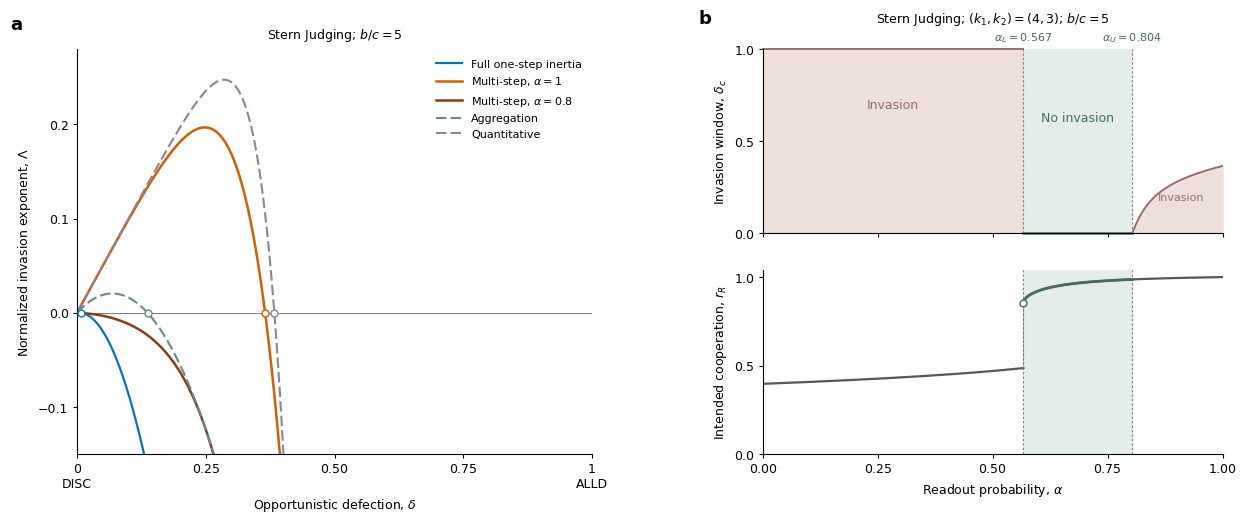

Saved two panels and their combined figure in PDF and SVG.


In [5]:
fig,ax=plt.subplots(figsize=(6.7,4.7))
draw_panel_a(ax)
fig.tight_layout()
save_figure(fig,'panel_a')
plt.close(fig)

fig=plt.figure(figsize=(5.7,5.0))
grid=fig.add_gridspec(2,1,left=.16,right=.96,bottom=.13,top=.91,hspace=.20)
top=fig.add_subplot(grid[0]);bottom=fig.add_subplot(grid[1],sharex=top)
draw_panel_b(top,bottom)
save_figure(fig,'panel_b')
plt.close(fig)

fig=plt.figure(figsize=(12.8,5.4))
grid=fig.add_gridspec(1,2,left=.075,right=.97,bottom=.16,top=.91,wspace=.35,
                      width_ratios=[1.12,1])
ax=fig.add_subplot(grid[0])
sub=grid[1].subgridspec(2,1,hspace=.20)
top=fig.add_subplot(sub[0]);bottom=fig.add_subplot(sub[1],sharex=top)
draw_panel_a(ax);draw_panel_b(top,bottom)
ax.text(-.13,1.05,'a',transform=ax.transAxes,fontweight='bold',fontsize=13)
top.text(-.14,1.14,'b',transform=top.transAxes,fontweight='bold',fontsize=13)
save_figure(fig,'Figure5_combined')
plt.show()
plt.close(fig)
assert len(list(FIGURES.glob('*.pdf')))==len(list(FIGURES.glob('*.svg')))==3
print('Saved two panels and their combined figure in PDF and SVG.')